# Session 12 Data for Machine Learning

**Learning goals:**

- Classify examples as structured, semi-structured or unstructured, and labelled or unlabelled.
- Distinguish model parameters from hyperparameters.
- Inspect a pandas DataFrame and compare methods for handling missing values.
- Select, filter and sort customer records.
- Transform, summarise, combine and plot data using pandas.
- Explain how preprocessing prepares features for machine learning.

**Prerequisites:**

- Python variables, lists, dictionaries, functions and comparison operators.
- Data, features, and targets from Session 11.
- Python 3 and a Jupyter-compatible notebook environment.
- pandas and matplotlib.

Install the required packages from a terminal if needed:

```bash
python -m pip install pandas matplotlib seaborn
```

## Outline

1. Data Categories
   - Structured, semi-structured and unstructured data
   - Labelled and unlabelled data
2. Model Attributes
   - Hyperparameters and parameters
3. Data Preprocessing in Pandas
   - Inspecting and cleaning
   - Selecting, filtering and sorting
   - Transforming and summarising
   - Combining with merge()
   - Plotting

## 1. Data Categories

### 1.1 Structured, Semi-structured and Unstructured Data

| Category | Description | Examples |
| --- | --- | --- |
| Structured | Consistent rows, columns, and data types | CSV tables, Excel tables, database tables |
| Semi-structured | Keys or tags provide some organisation, but the shape may vary | JSON, XML, API responses |
| Unstructured | No ready-made table of observations and attributes | free-form text, images, audio, documents |



### 1.2 Labelled and Unlabelled Data

| Category | Meaning | Typical use |
| --- | --- | --- |
| Labelled | Each training observation has a known target | supervised learning |
| Unlabelled | Observations do not have a target | clustering and other unsupervised learning |

Structure and labelling describe different aspects of data. A table can be unlabelled, while a collection of unstructured images can be labelled with categories.

| Example | Structure | Labelling |
| --- | --- | --- |
| customer table with a `renewed` column | structured | labelled |
| customer table without an outcome column | structured | unlabelled |
| support messages with issue categories | unstructured | labelled |
| raw support messages only | unstructured | unlabelled |

## 2. Model Attributes

| Model attribute | Definition | When determined | How obtained | Purpose | Examples |
| --- | --- | --- | --- | --- | --- |
| **Hyperparameters** | Settings that control model structure or learning | Before training | Chosen by the user; can be tuned using validation results | Control how the model learns | Tree depth; number of trees; learning rate |
| **Parameters** | Internal values learnt from training data | During training | Calculated by the learning algorithm | Represent learnt patterns used for predictions | Regression slope and intercept; tree split thresholds; neural-network weights and biases |


## 3. Data Preprocessing in Pandas

Preprocessing prepares data for analysis and machine-learning algorithms. Here we inspect customer records and fill missing values, select useful information, transform values, calculate summaries, combine tables and produce plots.

The examples demonstrate each operation on a small dataset. In a modelling workflow, calculate fill values from training data only, then reuse them for new data. Using all records to learn fill values can cause data leakage.

### 3.1 Inspecting and Cleaning

#### 3.1.1 Load and Inspect the Data

`pd.read_csv()` loads the customer CSV as a pandas DataFrame.

In [1]:
# Import pandas for loading and working with table data.
import pandas as pd

CSV_PATH = 'sample_data/ml_customer_data.csv'
customers_from_csv = pd.read_csv(CSV_PATH)

# .head() previews the first five rows.
customers_from_csv.head()

,customer_id,age,monthly_spend,visits_per_month,channel,region,renewed
0,C001,29.0,82.0,8,Web,North,1
1,C002,44.0,55.0,4,Store,South,0
2,C003,35.0,64.0,5,Phone,East,1
3,C004,23.0,40.0,6,Web,North,1
4,C005,52.0,91.0,3,Store,South,0


Inspect data before choosing transformations.

| Check | pandas tool |
| --- | --- |
| Rows and columns | `.shape` |
| Column names | `.columns` |
| Types and non-missing counts | `.info()` |
| Data types | `.dtypes` |
| Missing values | `.isna().sum()` |
| Repeated identifiers | `.duplicated(subset='customer_id')` |

In [2]:
# .copy() creates a working DataFrame without changing the imported source.
customers_raw = customers_from_csv.copy()

# .shape checks size; duplicated() and isna() identify common quality problems.
print('Rows and columns:', customers_raw.shape)
print('Duplicate rows:', customers_raw.duplicated().sum())
print('\nMissing values:')
print(customers_raw.isna().sum())

# .dtypes shows how pandas interpreted each column.
print('\nData types:')
print(customers_raw.dtypes)

Rows and columns: (33, 7)
Duplicate rows: 1

Missing values:
customer_id         0
age                 1
monthly_spend       1
visits_per_month    0
channel             1
region              0
renewed             0
dtype: int64

Data types:
customer_id             str
age                 float64
monthly_spend       float64
visits_per_month      int64
channel                 str
region                  str
renewed               int64
dtype: object


In [3]:
# columns lists the attributes; info() reports types and non-missing counts.
print('Column names:', customers_raw.columns.tolist())
customers_raw.info()

# keep=False marks every occurrence of a repeated customer identifier.
duplicate_customers = customers_raw.loc[
    customers_raw.duplicated(subset='customer_id', keep=False)
]
duplicate_customers

Column names: ['customer_id', 'age', 'monthly_spend', 'visits_per_month', 'channel', 'region', 'renewed']
<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       33 non-null     str    
 1   age               32 non-null     float64
 2   monthly_spend     32 non-null     float64
 3   visits_per_month  33 non-null     int64  
 4   channel           32 non-null     str    
 5   region            33 non-null     str    
 6   renewed           33 non-null     int64  
dtypes: float64(2), int64(2), str(3)
memory usage: 1.9 KB


,customer_id,age,monthly_spend,visits_per_month,channel,region,renewed
7,C008,27.0,48.0,5,Web,South,0
32,C008,27.0,48.0,5,Web,South,0


The CSV contains 33 records and seven columns. Customer `C008` appears twice with identical values. There are missing ages, spending values and a channel; `web`, ` Store ` and `Online` need consistent representation. Age `150` and spending `-20` also need investigation.

Matching identifiers with conflicting values would require investigation rather than automatically keeping the first record.

#### 3.1.2 Handle Missing Values

The following examples fill existing missing values. Repeated records, invalid numeric values and inconsistent channel names remain in the source data; filling alone does not resolve them.

pandas provides two common ways to handle missing values:

| Method | Operation | Example pattern |
| --- | --- | --- |
| `.dropna()` | Remove rows or columns containing missing values | `numeric_demo.dropna()` |
| `.fillna()` | Replace missing values with a selected value | `numeric_demo.fillna(numeric_demo.median())` |

`dropna()` handles missing data by removing it; it is not imputation. `fillna()` performs imputation when it replaces missing values with values such as:

- the median for numeric attributes
- the most frequent value, or mode, for categorical attributes

The following syntax demonstration uses six rows only.

In [4]:
# Select the numeric features used for missing-value handling.
numeric_columns = ['age', 'monthly_spend', 'visits_per_month']

# .iloc[] selects a small numeric subset containing missing values.
numeric_demo = customers_raw[
    ['age', 'monthly_spend', 'visits_per_month']
].iloc[[0, 13, 14, 16, 17, 24]]

# dropna() removes any row that contains a missing value.
numeric_complete_rows = numeric_demo.dropna()
print('Rows retained by dropna():', len(numeric_complete_rows))

# median() calculates one fill value per numeric column.
# fillna() replaces missing values while retaining all six rows.
numeric_imputed = numeric_demo.fillna(numeric_demo.median())

numeric_imputed

Rows retained by dropna(): 4


,age,monthly_spend,visits_per_month
0,29.0,82.0,8
13,29.0,84.0,4
14,29.0,105.0,9
16,26.0,-20.0,6
17,150.0,84.0,7
24,54.0,115.0,10


The six-row example lets you compare dropping incomplete rows with retaining them through imputation. Next, create a filled copy for the remaining analysis. Numeric medians and the most frequent channel are simple choices; neither reconstructs the original missing information.

In [5]:
# median() calculates one fill value for each numeric feature.
numeric_fill_values = customers_raw[numeric_columns].median()

# mode() returns the most frequent channel; iloc[0] selects the first mode.
channel_fill_value = customers_raw['channel'].mode().iloc[0]
customers_prepared = customers_raw.copy()
customers_prepared[numeric_columns] = customers_prepared[numeric_columns].fillna(
    numeric_fill_values
)
customers_prepared['channel'] = customers_prepared['channel'].fillna(
    channel_fill_value
)

# Check the result rather than assuming every missing value was filled.
print('Numeric fill values:')
print(numeric_fill_values)
print('Channel fill value:', channel_fill_value)
print('Missing values after filling:')
print(customers_prepared.isna().sum())

Numeric fill values:
age                 37.5
monthly_spend       71.0
visits_per_month     6.0
dtype: float64
Channel fill value: Web
Missing values after filling:
customer_id         0
age                 0
monthly_spend       0
visits_per_month    0
channel             0
region              0
renewed             0
dtype: int64


`customers_raw` preserves the imported records; `customers_prepared` fills their missing values. It still contains the repeated customer, age 150, spend -20 and inconsistent channel names.


### 3.2 Selecting, Filtering and Sorting

| Function | What it does | Example pattern |
| --- | --- | --- |
| `df[condition]` | Filter rows using a Boolean condition | `df[df['monthly_spend'] >= threshold]` |
| `df[[column_list]]` | Select multiple columns by name | `df[['customer_id', 'monthly_spend']]` |
| `.sort_values()` | Sort rows using one or more columns | `df.sort_values('monthly_spend', ascending=False)` |
| `.head()` / `.tail()` | Preview the first or last rows | `df.head(5)` |

In [6]:
# loc selects labelled rows and columns; iloc selects positions.
print('First three customers with selected columns:')
print(customers_prepared.loc[:, ['customer_id', 'age', 'monthly_spend']].head(3))
print('First three rows and first two columns by position:')
print(customers_prepared.iloc[:3, :2])

# isin selects named regions; & combines conditions, each in parentheses.
regional_web_customers = customers_prepared.loc[
    (customers_prepared['region'].isin(['North', 'South']))
    & (customers_prepared['channel'] == 'Web'),
    ['customer_id', 'region', 'channel', 'monthly_spend']
]
regional_web_customers

First three customers with selected columns:
  customer_id   age  monthly_spend
0        C001  29.0           82.0
1        C002  44.0           55.0
2        C003  35.0           64.0
First three rows and first two columns by position:
  customer_id   age
0        C001  29.0
1        C002  44.0
2        C003  35.0


,customer_id,region,channel,monthly_spend
0,C001,North,Web,82.0
3,C004,North,Web,40.0
7,C008,South,Web,48.0
14,C015,North,Web,105.0
18,C019,South,Web,73.0
22,C023,North,Web,78.0
24,C025,North,Web,115.0
28,C029,South,Web,45.0
30,C031,North,Web,93.0
32,C008,South,Web,48.0


In [7]:
# median() creates a reusable threshold for the filtering example.
spend_threshold = customers_prepared['monthly_spend'].median()

# DataFrame[condition] filters rows using the Boolean comparison result.
selected_customers = customers_prepared[
    customers_prepared['monthly_spend'] >= spend_threshold
]

# DataFrame[[column_list]] selects the columns returned by the filter.
selected_customers = selected_customers[
    ['customer_id', 'region', 'channel', 'monthly_spend', 'renewed']
]

# sort_values() orders the rows; head() previews the first eight results.
selected_customers = selected_customers.sort_values(
    'monthly_spend',
    ascending=False
)
selected_customers.head(8)

,customer_id,region,channel,monthly_spend,renewed
24,C025,North,Web,115.0,1
6,C007,North,Phone,110.0,1
14,C015,North,Web,105.0,1
19,C020,North,Store,98.0,1
12,C013,East,Online,95.0,1
30,C031,North,Web,93.0,1
4,C005,South,Store,91.0,0
27,C028,North,Phone,89.0,1


The Boolean comparison produces one True/False value per row. Selecting columns changes the information shown; sorting changes the order, rather than the records themselves. Use `tail()` to inspect the other end of a sorted table.


### 3.3 Transforming and Summarising

| Function | What it does | Example pattern |
| --- | --- | --- |
| `.assign()` | Create one or more transformed columns | `df.assign(new_column=values)` |
| `.map()` | Map individual values through a dictionary or function | `series.map({0: 'No', 1: 'Yes'})` |
| `.replace()` | Replace selected values | `series.replace({'Online': 'Web'})` |
| `.rename()` | Rename rows or columns | `df.rename(columns={'old': 'new'})` |
| `pd.cut()` | Divide numeric values into defined ranges | `pd.cut(series, bins=..., labels=...)` |
| `.groupby()` | Divide rows into groups | `df.groupby('region')` |
| `.agg()` | Calculate one or more group summaries | `.agg(total=('sales', 'sum'))` |

In [8]:
# Spending thresholds define illustrative bands, rather than learnt categories.
SPEND_BINS = [-float('inf'), 60, 90, float('inf')]
SPEND_LABELS = ['Low', 'Medium', 'High']

# assign() adds a mapped label and a spend band without changing customers_prepared.
wrangled_customers = (
    customers_prepared
    .assign(
        renewal_status=customers_prepared['renewed'].map({0: 'No', 1: 'Yes'}),
        spend_band=pd.cut(
            customers_prepared['monthly_spend'],
            bins=SPEND_BINS,
            labels=SPEND_LABELS
        )
    )
    .rename(columns={'visits_per_month': 'monthly_visits'})
)

# groupby() and agg() calculate several named summaries for each region.
region_summary = (
    wrangled_customers
    .groupby('region', as_index=False)
    .agg(
        customer_count=('customer_id', 'nunique'),
        average_monthly_spend=('monthly_spend', 'mean'),
        average_monthly_visits=('monthly_visits', 'mean'),
        renewal_rate=('renewed', 'mean')
    )
    .sort_values('average_monthly_spend', ascending=False)
)

# round() makes the displayed summary values easier to read.
region_summary.round(2)

,region,customer_count,average_monthly_spend,average_monthly_visits,renewal_rate
1,North,12,86.58,7.42,0.83
2,South,10,62.73,4.55,0.27
0,East,8,61.25,5.25,0.62
3,West,2,54.00,3.50,0.00


`pd.cut()` uses right-closed intervals by default: spend of 60 belongs to Low, and spend of 90 belongs to Medium. The `renewal_status` column provides readable target labels; it must not become an input feature for predicting `renewed`.

The regional summary reports unique customers, average spend, average visits and the observed renewal proportion. A mean of a 0/1 target is the proportion of rows with value 1. These summaries include imputed values.

In [9]:
# describe() summarises numeric values; value_counts() counts each category.
print(customers_prepared[numeric_columns].describe().round(2))
print('Customers by channel:')
print(customers_prepared['channel'].value_counts())

          age  monthly_spend  visits_per_month
count   33.00          33.00             33.00
mean    41.86          70.52              5.70
std     21.93          25.33              2.04
min     23.00         -20.00              2.00
25%     30.00          57.00              4.00
50%     37.50          71.00              6.00
75%     46.00          88.00              7.00
max    150.00         115.00             10.00
Customers by channel:
channel
Web        14
Store       8
Phone       8
web         1
 Store      1
Online      1
Name: count, dtype: int64


### 3.4 Combining Data with merge()

`merge()` joins tables by matching key values. The table before `.merge()` is the left table; the table supplied as its first argument is the right table. `on` selects the key and `how` determines which keys are retained.

| Join | Keys retained | Unmatched values |
| --- | --- | --- |
| `left` | All keys in the left table | Missing values in right-table columns |
| `right` | All keys in the right table | Missing values in left-table columns |
| `inner` | Keys present in both tables | Unmatched records are excluded |
| `outer` | Keys present in either table | Missing values on the side without a match |

The lookup below uses illustrative market types. `validate='one_to_one'` checks that the regional summary and lookup each have unique keys. Repeated keys can produce multiple matched rows, so the join type alone does not determine the row count.

[Pandas merge documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)

In [10]:
# Build a lookup with one illustrative market type for each region.
region_lookup = pd.DataFrame({
    'region': ['North', 'South', 'East', 'West'],
    'market_type': ['Established', 'Growth', 'Growth', 'Emerging']
})

# how='left' retains summary regions; on selects the shared key.
# validate checks that each key occurs once in each table.
region_enriched = region_summary.merge(
    region_lookup,
    how='left',
    on='region',
    validate='one_to_one'
)
region_enriched

,region,customer_count,average_monthly_spend,average_monthly_visits,renewal_rate,market_type
0,North,12,86.583333,7.416667,0.833333,Established
1,South,10,62.727273,4.545455,0.272727,Growth
2,East,8,61.250000,5.250000,0.625000,Growth
3,West,2,54.000000,3.500000,0.000000,Emerging


All four regions match in the complete tables, so each join type would retain the same regions. To make the differences visible, use two subsets: the left table contains North, South and East; the right table contains North, South and West.

In [11]:
# isin selects different subsets so both sides have an unmatched region.
left_regions = region_summary.loc[
    region_summary['region'].isin(['North', 'South', 'East']),
    ['region', 'customer_count']
]
right_regions = region_lookup.loc[
    region_lookup['region'].isin(['North', 'South', 'West'])
]
print('Left table:')
print(left_regions.to_string(index=False))
print('Right table:')
print(right_regions.to_string(index=False))

Left table:
region  customer_count
 North              12
 South              10
  East               8
Right table:
region market_type
 North Established
 South      Growth
  West    Emerging


#### 3.4.1 Left Join

Retain North, South and East from the left table. East has no matching market type.

In [12]:
# how='left' controls which keys are retained.
# indicator=True adds _merge to identify left-only, right-only and matched rows.
left_joined = left_regions.merge(
    right_regions,
    how='left',
    on='region',
    validate='one_to_one',
    indicator=True
)
left_joined

,region,customer_count,market_type,_merge
0,North,12,Established,both
1,South,10,Growth,both
2,East,8,NaN,left_only


#### 3.4.2 Right Join

Retain North, South and West from the right table. West has no matching customer count.

In [13]:
# how='right' controls which keys are retained.
# indicator=True adds _merge to identify left-only, right-only and matched rows.
right_joined = left_regions.merge(
    right_regions,
    how='right',
    on='region',
    validate='one_to_one',
    indicator=True
)
right_joined

,region,customer_count,market_type,_merge
0,North,12.0,Established,both
1,South,10.0,Growth,both
2,West,NaN,Emerging,right_only


#### 3.4.3 Inner Join

Retain North and South, which occur in both tables.

In [14]:
# how='inner' controls which keys are retained.
# indicator=True adds _merge to identify left-only, right-only and matched rows.
inner_joined = left_regions.merge(
    right_regions,
    how='inner',
    on='region',
    validate='one_to_one',
    indicator=True
)
inner_joined

,region,customer_count,market_type,_merge
0,North,12,Established,both
1,South,10,Growth,both


#### 3.4.4 Outer Join

Retain North, South, East and West. East and West each have values missing on the unmatched side.

In [15]:
# how='outer' controls which keys are retained.
# indicator=True adds _merge to identify left-only, right-only and matched rows.
outer_joined = left_regions.merge(
    right_regions,
    how='outer',
    on='region',
    validate='one_to_one',
    indicator=True
)
outer_joined

,region,customer_count,market_type,_merge
0,East,8.0,NaN,left_only
1,North,12.0,Established,both
2,South,10.0,Growth,both
3,West,NaN,Emerging,right_only


The `_merge` column contains `left_only`, `right_only` or `both`. It makes missing matches explicit. A missing customer count for West means the left subset has no record, rather than that West has zero customers.

### 3.5 Plotting Functions

**Matplotlib** is a Python library for creating static, animated and interactive visualisations. It provides detailed control over figures, axes, labels, colours and layout. Pandas uses Matplotlib as its default plotting backend, so the pandas charts in this section can be customised with Matplotlib.

[Matplotlib documentation](https://matplotlib.org/stable/)

**Seaborn** is a statistical visualisation library built on Matplotlib. It provides a higher-level interface for exploring distributions, relationships and differences between groups, with support for tabular data. Seaborn charts can also be customised using Matplotlib.

[Seaborn documentation](https://seaborn.pydata.org/)

pandas plotting methods provide quick visual checks and use Matplotlib as the plotting backend.

| Function | Plot type | Common use |
| --- | --- | --- |
| `.plot()` | line plot by default | show a trend or general relationship |
| `.plot.bar()` | bar chart | compare values across categories |
| `.plot.hist()` | histogram | inspect the distribution of one numeric attribute |
| `.plot.box()` | box plot | compare spread and possible extreme values |
| `.plot.scatter()` | scatter plot | inspect the relationship between two numeric attributes |

Each plotting function returns an axes object that can be further customised.

The next plots use pandas with Matplotlib. Each chart answers a different question. Regions are categories without a natural time order, so a bar chart is more suitable than a line chart for comparing them.

#### 3.5.1 Compare Regions

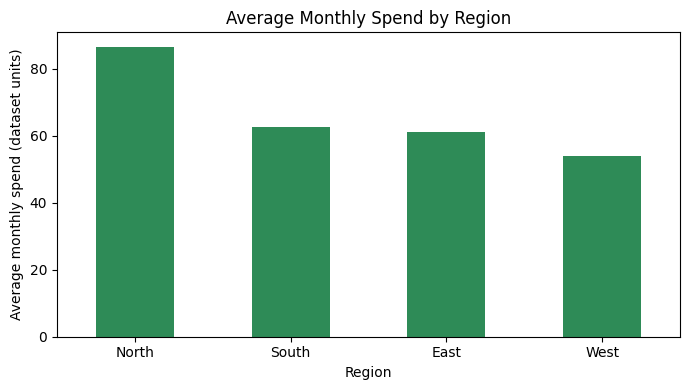

In [16]:
# Import Matplotlib at the first chart; show() presents the completed figure.
import matplotlib.pyplot as plt

# set_index gives the bars region labels; rot=0 keeps those labels horizontal.
region_summary.set_index('region')['average_monthly_spend'].plot.bar(
    color='seagreen',
    title='Average Monthly Spend by Region',
    xlabel='Region',
    ylabel='Average monthly spend (dataset units)',
    rot=0,
    figsize=(7, 4)
)
plt.tight_layout()
plt.show()

The bars compare mean spending, not total spending. Check group sizes alongside the means: the synthetic data represents regions unevenly.

#### 3.5.2 Inspect a Distribution

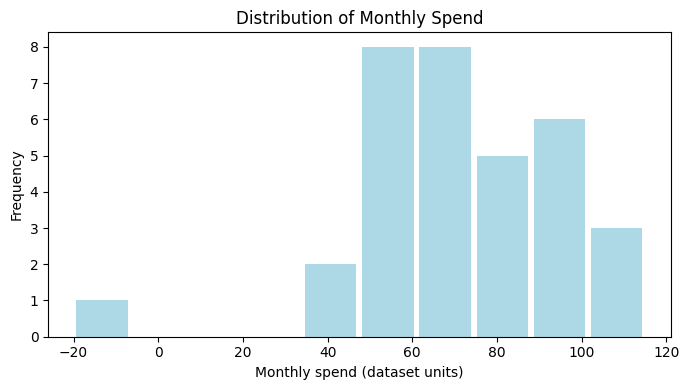

In [17]:
# plot.hist() shows how monthly-spend values are distributed.
SPEND_HISTOGRAM_BINS = 10
# bins creates ten intervals; rwidth leaves space between the bars.
# color sets the bars to light blue.
customers_prepared['monthly_spend'].plot.hist(
    bins=SPEND_HISTOGRAM_BINS,
    rwidth=0.9,
    color='lightblue',
    title='Distribution of Monthly Spend',
    xlabel='Monthly spend (dataset units)',
    figsize=(7, 4)
)
plt.tight_layout()
plt.show()

The histogram groups spending into intervals and shows how many customers fall within each. Filling missing values can change a distribution, so distinguish observed and imputed values when interpreting it.

#### 3.5.3 Inspect Spread and Possible Extreme Values

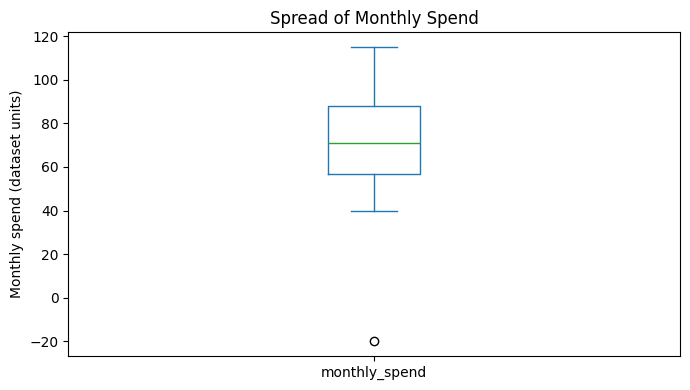

In [18]:
# plot.box displays quartiles, a median and potential extreme observations.
customers_prepared[['monthly_spend']].plot.box(
    title='Spread of Monthly Spend',
    ylabel='Monthly spend (dataset units)',
    figsize=(7, 4)
)
plt.tight_layout()
plt.show()

A point outside the whiskers is a reason to investigate, not proof of an error. Compare it with the meaning and valid range of the feature.

#### 3.5.4 Inspect a Relationship

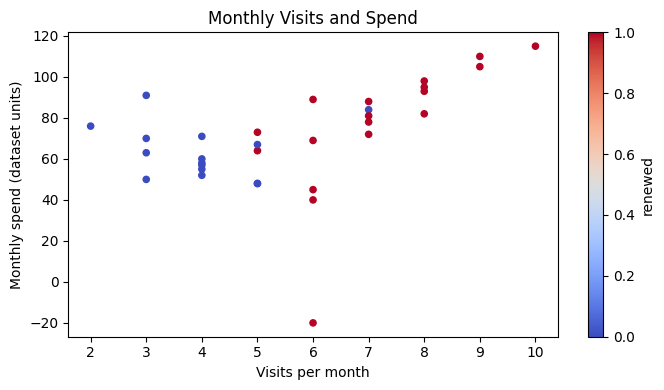

In [19]:
# plot.scatter() compares monthly visits with monthly spend.
# c selects the target attribute; colormap maps its values to colours.
customers_prepared.plot.scatter(
    x='visits_per_month',
    y='monthly_spend',
    c='renewed',
    colormap='coolwarm',
    title='Monthly Visits and Spend',
    xlabel='Visits per month',
    ylabel='Monthly spend (dataset units)',
    figsize=(7, 4)
)
plt.tight_layout()
plt.show()

Each point represents one customer record; its colour represents `renewed` (0 or 1). The plot can show an association between visits, spend and renewal, but it cannot establish causation or performance on new customers.
